# Ejercicio 1: una imagen como matriz y como vector

En este ejercicio construimos una imagen fantoma de $8 \times 8$ píxeles y estudiamos su representación en forma de matriz y de vector.

In [28]:
import numpy as np
import matplotlib.pyplot as plt

In [29]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

## a) Visualización de la imagen fantoma

Visualizamos la matriz `X_fantoma` como una imagen en escala de grises. 

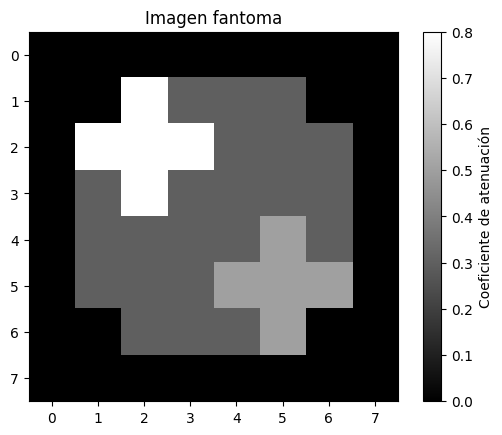

In [30]:
plt.imshow(X_fantoma, cmap="gray")
plt.title("Imagen fantoma")
plt.colorbar(label="Coeficiente de atenuación")
plt.show()

## b) Vectorización de la matriz

Convertimos la matriz de $8 \times 8$ en un vector de 64 componentes mediante `reshape(-1)`. 


In [31]:
x_fantoma = X_fantoma.reshape(-1)

print (x_fantoma.shape) # verificamos sus dimensiones

(64,)


## c) Recuperación de la matriz original

A partir de `x_fantoma` recuperamos la matriz de $8 \times 8$ original y comparamos ambas matrices para comprobar que contienen exactamente la misma información. 

In [32]:
X_fantoma_recuperada = x_fantoma.reshape(8,8)

np.all(X_fantoma_recuperada == X_fantoma)

True

## d) Interpretación de los valores de los píxeles

El valor de una componente $x_k$ representa el coeficiente de atenuación del píxel correspondiente. 

- Un valor alto indica que esa región atenúa más el rayo, por lo que llega una menor intensidad al detector. 
- Un valor bajo indica que la región atenúa menos el rayo y permite que una mayor intensidad lo atraviese. 
- Un valor nulo indica que ese píxel no produce atenuación.

## e) Modificación de un píxel y localización en el vector



In [33]:
X_modificada = X_fantoma.copy()
X_modificada[1,7] = 0.9

x_modificada = X_modificada.reshape(-1)
posiciones_cambiadas = np.where(x_fantoma != x_modificada)[0]
print(posiciones_cambiadas)

[15]


Modificamos el píxel ubicado en la fila 1 y la columna 7, y comparamos los vectores original y modificado para localizar la componente que cambió. Como los índices comienzan en cero y la matriz se vectoriza por filas, la relación entre la posición $(i,j)$ de un píxel y su posición $k$ en el vector es $k=i\cdot n+j$, siendo $n$ la cantidad de columnas. En este caso, como $n=8$, la relación es $k=8i+j$. Para el píxel ubicado en $(1,7)$ se obtiene $k=8\cdot1+7=15$, lo que coincide con la posición 15 detectada numéricamente.